# Fake News Detection — Algorithm 4 (A4): Naive Bayes

This notebook implements **A4 — Naive Bayes** (Multinomial Naive Bayes), using the same pipeline and 80:20 split (`random_state=42`) as A1 (Logistic Regression), A2 (SVM) and A3 (Random Forest) in the project report, so all four sets of results are directly comparable.

**Dataset:** `fake_or_real_news.csv` (George McIntire's Fake/Real News dataset, ~6,335 labeled articles, binary REAL/FAKE).

In [1]:
# Step 1: Imports
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

sns.set_style("whitegrid")
pd.set_option("display.max_colwidth", 80)
RANDOM_STATE = 42

In [2]:
# Step 2: Load the labeled dataset
df = pd.read_csv("fake_or_real_news.csv")
print("Shape:", df.shape)
df.head()

Shape: (6335, 4)


,id,title,text,label
0,8476,You Can Smell Hillary’s Fear,"Daniel Greenfield, a Shillman Journalism Fellow at the Freedom Center, is a ...",FAKE
1,10294,Watch The Exact Moment Paul Ryan Committed Political Suicide At A Trump Rall...,Google Pinterest Digg Linkedin Reddit Stumbleupon Print Delicious Pocket Tum...,FAKE
2,3608,Kerry to go to Paris in gesture of sympathy,U.S. Secretary of State John F. Kerry said Monday that he will stop in Paris...,REAL
3,10142,Bernie supporters on Twitter erupt in anger against the DNC: 'We tried to wa...,"— Kaydee King (@KaydeeKing) November 9, 2016 The lesson from tonight's Dem l...",FAKE
4,875,The Battle of New York: Why This Primary Matters,It's primary day in New York and front-runners Hillary Clinton and Donald Tr...,REAL


In [3]:
# Step 3: Inspect rows, columns, missing values and class distribution
print(df.info())
print("\nMissing values per column:\n", df.isnull().sum())
print("\nClass distribution:\n", df['label'].value_counts())

<class 'pandas.DataFrame'>
RangeIndex: 6335 entries, 0 to 6334
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   id      6335 non-null   int64
 1   title   6335 non-null   str  
 2   text    6335 non-null   str  
 3   label   6335 non-null   str  
dtypes: int64(1), str(3)
memory usage: 198.1 KB
None

Missing values per column:
 id       0
title    0
text     0
label    0
dtype: int64

Class distribution:
 label
REAL    3171
FAKE    3164
Name: count, dtype: int64


In [4]:
# Step 4: Handle missing or invalid text records
df = df.dropna(subset=['title', 'text', 'label']).copy()
df = df[(df['text'].str.strip() != '') & (df['title'].str.strip() != '')]
df = df.reset_index(drop=True)
print("Shape after cleaning missing/invalid records:", df.shape)

Shape after cleaning missing/invalid records: (6299, 4)


In [5]:
# Step 5: Combine title and text fields
df['content'] = df['title'].astype(str) + " " + df['text'].astype(str)
df[['title', 'content']].head(2)

,title,content
0,You Can Smell Hillary’s Fear,"You Can Smell Hillary’s Fear Daniel Greenfield, a Shillman Journalism Fellow..."
1,Watch The Exact Moment Paul Ryan Committed Political Suicide At A Trump Rall...,Watch The Exact Moment Paul Ryan Committed Political Suicide At A Trump Rall...


In [6]:
# Step 6: Preprocess the text (lowercasing, removing punctuation/special characters,
# removing digits and extra whitespace). Stopword removal is handled by TfidfVectorizer.

def preprocess_text(text):
    text = text.lower()
    text = re.sub(r'http\S+|www\.\S+', ' ', text)      # remove URLs
    text = re.sub(r'[^a-z\s]', ' ', text)               # remove punctuation & digits
    text = re.sub(r'\s+', ' ', text).strip()             # collapse whitespace
    return text

df['clean_content'] = df['content'].apply(preprocess_text)
df[['content', 'clean_content']].head(2)

,content,clean_content
0,"You Can Smell Hillary’s Fear Daniel Greenfield, a Shillman Journalism Fellow...",you can smell hillary s fear daniel greenfield a shillman journalism fellow ...
1,Watch The Exact Moment Paul Ryan Committed Political Suicide At A Trump Rall...,watch the exact moment paul ryan committed political suicide at a trump rall...


In [7]:
# Step 7: Apply TfidfVectorizer with the same parameters used for A1-A3
# Note: MultinomialNB requires non-negative feature values, which TF-IDF
# already satisfies (unlike, say, mean-centered features), so no extra
# transformation is needed here.
tfidf = TfidfVectorizer(
    stop_words='english',
    max_features=5000,
    ngram_range=(1, 1)
)

X = tfidf.fit_transform(df['clean_content'])
y = df['label']

print("TF-IDF feature matrix shape:", X.shape)

TF-IDF feature matrix shape: (6299, 5000)


In [8]:
# Step 8: Split data into training and testing sets (80:20), same split as A1-A3
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Train shape:", X_train.shape, " Test shape:", X_test.shape)

Train shape: (5039, 5000)  Test shape: (1260, 5000)


In [9]:
# Step 9: Initialize MultinomialNB (A4)
nb_model = MultinomialNB()
nb_model

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None


In [10]:
# Step 10: Train the model
nb_model.fit(X_train, y_train)
print("A4 (Naive Bayes) training complete.")

A4 (Naive Bayes) training complete.


In [11]:
# Step 11: Predict test labels
y_pred_nb = nb_model.predict(X_test)
y_pred_nb[:10]

array(['FAKE', 'REAL', 'REAL', 'REAL', 'REAL', 'REAL', 'FAKE', 'FAKE',
       'FAKE', 'REAL'], dtype='<U4')

In [12]:
# Step 12: Calculate accuracy, precision, recall and F1-score
acc_nb = accuracy_score(y_test, y_pred_nb)
prec_nb = precision_score(y_test, y_pred_nb, pos_label='FAKE')
rec_nb = recall_score(y_test, y_pred_nb, pos_label='FAKE')
f1_nb = f1_score(y_test, y_pred_nb, pos_label='FAKE')

print(f"A4 - Naive Bayes Results")
print(f"Accuracy : {acc_nb:.4f}")
print(f"Precision: {prec_nb:.4f}")
print(f"Recall   : {rec_nb:.4f}")
print(f"F1-score : {f1_nb:.4f}")
print("\nFull classification report:\n")
print(classification_report(y_test, y_pred_nb))

A4 - Naive Bayes Results
Accuracy : 0.8714
Precision: 0.8537
Recall   : 0.8946
F1-score : 0.8736

Full classification report:

              precision    recall  f1-score   support

        FAKE       0.85      0.89      0.87       626
        REAL       0.89      0.85      0.87       634

    accuracy                           0.87      1260
   macro avg       0.87      0.87      0.87      1260
weighted avg       0.87      0.87      0.87      1260



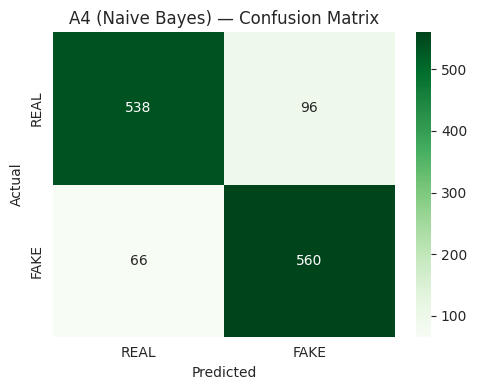

In [13]:
# Step 13: Generate a confusion matrix
cm_nb = confusion_matrix(y_test, y_pred_nb, labels=['REAL', 'FAKE'])

plt.figure(figsize=(5, 4))
sns.heatmap(cm_nb, annot=True, fmt='d', cmap='Greens',
            xticklabels=['REAL', 'FAKE'], yticklabels=['REAL', 'FAKE'])
plt.title("A4 (Naive Bayes) — Confusion Matrix")
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.tight_layout()
plt.show()

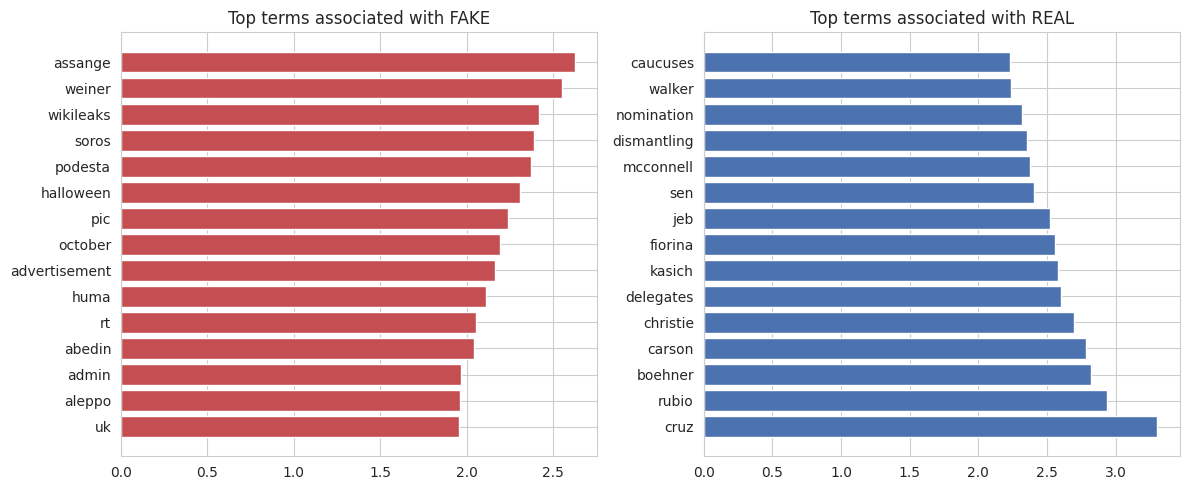

In [14]:
# Step 14: Inspect the terms most strongly associated with each class
# (largest log-probability difference between FAKE and REAL)
feature_names = np.array(tfidf.get_feature_names_out())
log_prob_fake = nb_model.feature_log_prob_[list(nb_model.classes_).index('FAKE')]
log_prob_real = nb_model.feature_log_prob_[list(nb_model.classes_).index('REAL')]
log_ratio = log_prob_fake - log_prob_real

top_n = 15
top_fake_idx = np.argsort(log_ratio)[-top_n:]   # most associated with FAKE
top_real_idx = np.argsort(log_ratio)[:top_n]    # most associated with REAL

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].barh(feature_names[top_fake_idx], log_ratio[top_fake_idx], color='#C44E52')
axes[0].set_title("Top terms associated with FAKE")
axes[1].barh(feature_names[top_real_idx], -log_ratio[top_real_idx], color='#4C72B0')
axes[1].set_title("Top terms associated with REAL")
plt.tight_layout()
plt.show()

In [15]:
# Step 15: Train A1 (Logistic Regression), A2 (SVM) and A3 (Random Forest)
# for comparison, using the exact same split
lr_model = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
lr_model.fit(X_train, y_train)
y_pred_lr = lr_model.predict(X_test)

svm_model = LinearSVC(random_state=RANDOM_STATE)
svm_model.fit(X_train, y_train)
y_pred_svm = svm_model.predict(X_test)

rf_model = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)

print("A1 (Logistic Regression), A2 (SVM) and A3 (Random Forest) trained.")

A1 (Logistic Regression), A2 (SVM) and A3 (Random Forest) trained.


In [16]:
# Step 16: Compare all four algorithms in a results DataFrame
def get_metrics(name, y_true, y_pred):
    return {
        'Algorithm': name,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, pos_label='FAKE'),
        'Recall': recall_score(y_true, y_pred, pos_label='FAKE'),
        'F1-score': f1_score(y_true, y_pred, pos_label='FAKE'),
    }

results = pd.DataFrame([
    get_metrics('A1 - Logistic Regression', y_test, y_pred_lr),
    get_metrics('A2 - SVM', y_test, y_pred_svm),
    get_metrics('A3 - Random Forest', y_test, y_pred_rf),
    get_metrics('A4 - Naive Bayes', y_test, y_pred_nb),
])
results = results.set_index('Algorithm').round(4)
results

,Accuracy,Precision,Recall,F1-score
Algorithm,,,,
A1 - Logistic Regression,0.9183,0.9042,0.9345,0.9191
A2 - SVM,0.9357,0.9360,0.9345,0.9353
A3 - Random Forest,0.9048,0.9003,0.9089,0.9046
A4 - Naive Bayes,0.8714,0.8537,0.8946,0.8736


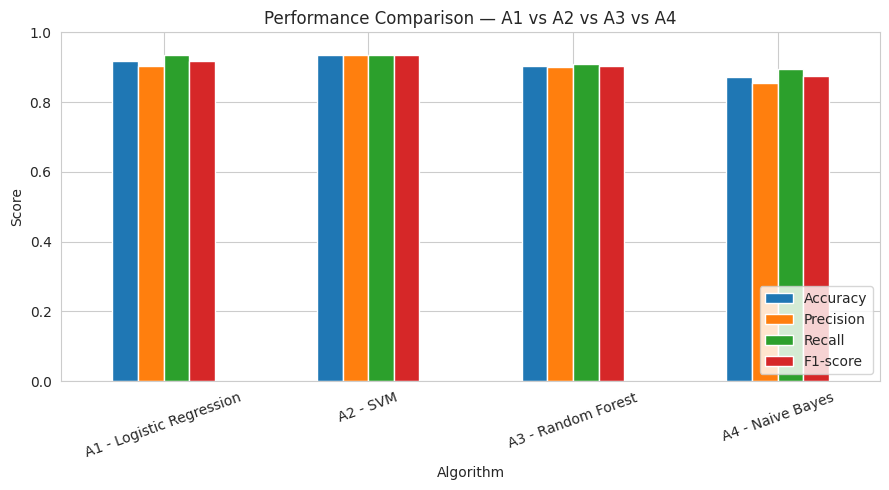

In [17]:
# Visualize the comparison
results.plot(kind='bar', figsize=(9, 5))
plt.title("Performance Comparison — A1 vs A2 vs A3 vs A4")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

In [18]:
# Step 17: Select the best model based on evaluation results
best_model_name = results['F1-score'].idxmax()
print(f"Best-performing model (by F1-score): {best_model_name}")
results.loc[[best_model_name]]

Best-performing model (by F1-score): A2 - SVM


,Accuracy,Precision,Recall,F1-score
Algorithm,,,,
A2 - SVM,0.9357,0.936,0.9345,0.9353


## Execution Example

Testing the trained A4 (Naive Bayes) pipeline on the same illustrative article used for A1-A3, for a direct comparison.

In [19]:
# Step 18: Test A4 on the same new-article example used for A1/A2/A3
new_article = (
    "Breaking News: Scientists discover cure for all known diseases in a "
    "small village in Switzerland. The discovery was made by a team of "
    "researchers who have been working on the project for the past decade. "
    "The cure is expected to be available to the public within the next month."
)

clean_new = preprocess_text(new_article)
new_vec = tfidf.transform([clean_new])

pred_class = nb_model.predict(new_vec)[0]
pred_proba = nb_model.predict_proba(new_vec)[0]
class_labels = nb_model.classes_
confidence = pred_proba[list(class_labels).index(pred_class)]

print("Input article:", new_article)
print(f"\nPredicted class : {pred_class}")
print(f"Confidence      : {confidence*100:.1f}%")

Input article: Breaking News: Scientists discover cure for all known diseases in a small village in Switzerland. The discovery was made by a team of researchers who have been working on the project for the past decade. The cure is expected to be available to the public within the next month.

Predicted class : FAKE
Confidence      : 86.4%


## Conclusion (A4)

The Naive Bayes classifier (A4) was trained on the same TF-IDF features (max 5,000 terms, combined title+text) and the same 80:20 split (`random_state=42`) as A1-A3, using `MultinomialNB` with its default smoothing. Its accuracy, precision, recall, F1-score, confusion matrix and most class-indicative terms were computed above, and it was benchmarked against A1 (Logistic Regression), A2 (SVM) and A3 (Random Forest). It's the simplest and fastest of the four models to train, which is part of why it's a useful baseline even though it trails the others on most metrics here.